# EntregaCerta AI — VER0.7, do dado ao CatBoost

**Notebook didático, independente dos notebooks 01/02 e do modelo ativo.**
Vamos ler os dados reais, entender os tratamentos, explorar o treino, formar
os atributos em D−1, treinar o piloto CatBoost e avaliar sua fila de revisão.

**Como usar:** escolha o kernel indicado abaixo, confira os dois caminhos dos
ZIPs e use **Reiniciar Kernel → Executar Tudo**. Nenhuma célula depende do 02.
Cada execução salva seus resultados em uma pasta nova, sem trocar o modelo da aplicação.

| Etapa | Pergunta |
|---|---|
| 1–2. Ambiente e fontes | Quais arquivos e versões estamos usando? |
| 3. Tratamento | Como passamos de várias tabelas para um pedido por linha? |
| 4. Tempo e divisão | O que sabemos em D−1 e quais pedidos podem treinar? |
| 5–6. EDA e atributos | Como são os dados e quais sinais chegam ao modelo? |
| 7–9. Treino e avaliação | O CatBoost supera regras simples, com a mesma fila? |
| 10. Persistência | O modelo salvo reproduz os resultados? |

**Limite científico:** reproduzimos um experimento exploratório. O teste histórico
já foi reutilizado e a cota de 65% foi definida após exploração. Executar este
notebook não transforma esse teste em uma avaliação inédita.

## 1. Preparar o ambiente e entender o objetivo

**Problema:** um dia antes da entrega prometida, quais pedidos ainda pendentes
devem ser revisados primeiro? O alvo é `late`: 1 se a entrega ocorreu em um dia
posterior ao prometido; 0 caso contrário. É classificação supervisionada, não
estimativa de quantos dias o pedido atrasará nem identificação de causas.

**D−1** significa 00:00 do dia anterior à data prometida. Uma entrega prometida
para 20/08 será analisada no checkpoint de 19/08 às 00:00. Esse exemplo explica
o calendário; não é um registro usado no treino.

No VS Code, selecione **Python Environments → `.venv-ctgan`** neste computador:
é o ambiente de pesquisa já disponível. Não usaremos GAN nem dados sintéticos.
Em outro computador, crie um ambiente separado no terminal, na raiz do projeto:

```powershell
py -3.12 -m venv .venv-ver07
.\.venv-ver07\Scripts\python.exe -m pip install -r requirements-ver07.txt
```

Depois selecione `.venv-ver07` como kernel. Não instale pacotes automaticamente
durante o treino nem misture esse ambiente com o servidor que está aberto.
Este notebook não precisa de PostgreSQL nem de chave de API: o schema atual
contém entradas de validação/teste, enquanto o treinamento precisa das fontes
originais e dos registros históricos anteriores.

In [8]:
from pathlib import Path
from datetime import datetime, timezone
from time import perf_counter
from uuid import uuid4
import hashlib
import importlib.metadata
import json
import math
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown
from catboost import CatBoostClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             accuracy_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_curve)

# Funciona abrindo o notebook na raiz ou dentro de Notebooks.
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "main.py").is_file() and (p / "Dados").is_dir())
PACOTE = RAIZ / "experimentos/EntregaCertaAI_VER07"
sys.path.insert(0, str(PACOTE / "src"))
import benchmark_ver07 as ver07
import olist_checkpoint as checkpoint
import ver04_features as historicos
import external_features as externos
import benchmark_ver06 as ver06

VERSOES = {n: importlib.metadata.version(n) for n in
           ["pandas", "numpy", "catboost", "scikit-learn", "lightgbm", "optuna", "xgboost"]}
assert pd.__version__.split(".")[0] == "2", "Use o kernel de pesquisa com Pandas 2.x."
assert VERSOES["catboost"] == "1.2.10", "Use CatBoost 1.2.10 para comparar esta reprodução."
print("Python do kernel:", sys.executable)
display(pd.Series(VERSOES, name="Versão instalada").to_frame())
plt.rcParams.update({"figure.figsize": (10, 4.5), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlepad": 12, "figure.dpi": 110})
CORES = {"pontual": "#397186", "atraso": "#b84e36", "modelo": "#1b6b50"}

Python do kernel: c:\Users\cpedr\Documents\Documentos\TCS\projeto\EntregaCerta-AI\.venv\Scripts\python.exe


,Versão instalada
pandas,2.3.3
numpy,2.5.5
catboost,1.2.10
scikit-learn,1.9.1
lightgbm,4.7.0
optuna,5.1.0
xgboost,3.4.1


### 1.1. Configuração única e proteção das versões anteriores

Se seus ZIPs estiverem em outro lugar, altere **somente as duas primeiras linhas**.
Os parâmetros do piloto ficam fixos nesta reprodução. A pasta de saída recebe
data/hora e um identificador, evitando sobrescrever execuções anteriores.
Registramos hashes (impressões digitais) dos notebooks antigos, do pacote e
do modelo ativo para conferir sua preservação no final.

In [9]:
ARQUIVO_OLIST = Path.home() / "Downloads/logistic-brazilian-dataset.zip"
ARQUIVO_RODOVIAS = Path.home() / "Downloads/dist_brasil.zip"

SEMENTE = 42
FRACAO_FILA = 0.65
PARAMETROS = dict(iterations=420, depth=5, learning_rate=0.035,
                 l2_leaf_reg=12.0, auto_class_weights="Balanced",
                 random_strength=0.6, rsm=0.85, loss_function="Logloss",
                 random_seed=SEMENTE, thread_count=4, one_hot_max_size=10,
                 allow_writing_files=False, verbose=False)
EXECUCAO = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S") + "_" + uuid4().hex[:6]
SAIDA = RAIZ / "Modelos/notebook_ver07" / EXECUCAO

def sha256(caminho):
    with Path(caminho).open("rb") as arquivo:
        return hashlib.file_digest(arquivo, "sha256").hexdigest()

protegidos = list((RAIZ / "Notebooks").rglob("*.ipynb"))
protegidos += list(PACOTE.rglob("*"))
protegidos += list((RAIZ / "Modelos/catboost_ver07").glob("*"))
protegidos += [RAIZ / "Modelos/rede_neural.pt", RAIZ / "Modelos/preprocessador_rede.joblib"]
hashes_antes = {str(p): sha256(p) for p in protegidos if p.is_file()
               and "__pycache__" not in p.parts and p.suffix != ".log"
               and p.name != "03_catboost_ver07.ipynb"}
print("Saída desta execução:", SAIDA)
print("Arquivos anteriores protegidos:", len(hashes_antes))

Saída desta execução: c:\Users\cpedr\Documents\Documentos\TCS\projeto\EntregaCerta-AI\Modelos\notebook_ver07\20261117_231715_acb863
Arquivos anteriores protegidos: 68


## 2. Conferir e carregar as fontes

Usamos Olist real e anonimizado (2016–2018). Clima agregado por UF, cadastros
IBGE e marketing vêm dos CSVs preparados no pacote recebido. Não refazemos a
extração bruta do INMET aqui. A matriz rodoviária é de **2024**, portanto uma
aproximação posterior aos pedidos. Uma correspondência de hash confirma o
arquivo usado, não a qualidade ou representatividade de todos os registros.

O manifesto exige os ZIPs originais. Se houver divergência, investigue a fonte;
não remova o teste apenas para obter as contagens esperadas. Documentação:
[fontes Olist](../Docs/recebimento_dataset.txt) e
[limitações VER0.7](../Docs/modelo_ver07.md).

In [10]:
manifesto = json.loads((PACOTE / "manifesto_arquivos.json").read_text(encoding="utf-8"))
hashes_fontes = {}
for caminho in [ARQUIVO_OLIST, ARQUIVO_RODOVIAS]:
    assert caminho.is_file(), f"Arquivo ausente: {caminho}. Corrija a célula 1.1."
    hashes_fontes[caminho.name] = sha256(caminho)
    assert hashes_fontes[caminho.name] == manifesto["original_sha256"][caminho.name], caminho.name

PREPARADOS = PACOTE / "inputs_preparados"
for nome in ["weather_daily.csv", "municipios_ibge.csv", "olist_closed_deals_dataset.csv"]:
    caminho = PREPARADOS / nome
    assert caminho.is_file(), f"Fonte preparada ausente: {nome}"
    hashes_fontes[nome] = sha256(caminho)

# read_tables apenas lê os CSVs do ZIP e converte as colunas de datas dos pedidos.
pedidos, clientes, vendedores, itens, produtos, pagamentos, geo = checkpoint.read_tables(ARQUIVO_OLIST)
tabelas = {"pedidos": pedidos, "clientes": clientes, "vendedores": vendedores,
           "itens": itens, "produtos": produtos, "pagamentos": pagamentos, "geolocalização": geo}
inventario = pd.DataFrame([{"Tabela": nome, "Linhas": len(df), "Colunas": df.shape[1],
                            "Linhas idênticas": int(df.duplicated().sum())}
                           for nome, df in tabelas.items()])
display(inventario)

,Tabela,Linhas,Colunas,Linhas idênticas
0,pedidos,99441,8,0
1,clientes,99441,5,0
2,vendedores,3095,4,0
3,itens,112650,7,0
4,produtos,32951,9,0
5,pagamentos,103886,5,0
6,geolocalização,1000163,3,280009


### 2.1. Chaves, nulos e repetições

`order_id` identifica um pedido, mas aparece várias vezes em itens e pagamentos:
isso é esperado. Não podemos excluir essas linhas como duplicatas. A geolocalização
também tem várias observações por prefixo de CEP; usaremos uma mediana por prefixo.
`validate` nas junções verifica a relação esperada e evita multiplicar pedidos.

In [11]:
for df, chave in [(pedidos, "order_id"), (clientes, "customer_id"),
                  (vendedores, "seller_id"), (produtos, "product_id")]:
    assert df[chave].notna().all() and df[chave].is_unique, f"Chave inválida: {chave}"
assert not itens.duplicated(["order_id", "order_item_id"]).any()
assert not pagamentos.duplicated(["order_id", "payment_sequential"]).any()

qualidade_pedidos = pd.DataFrame({"Tipo": pedidos.dtypes.astype(str),
                                 "Ausentes": pedidos.isna().sum(),
                                 "Ausentes (%)": pedidos.isna().mean().mul(100).round(2)})
display(qualidade_pedidos)
display(pedidos.order_status.value_counts().rename_axis("Status original").to_frame("Pedidos"))

,Tipo,Ausentes,Ausentes (%)
order_id,object,0,0.00
customer_id,object,0,0.00
order_status,object,0,0.00
order_purchase_timestamp,datetime64[ns],0,0.00
order_approved_at,datetime64[ns],160,0.16
order_delivered_carrier_date,datetime64[ns],1783,1.79
order_delivered_customer_date,datetime64[ns],2965,2.98
order_estimated_delivery_date,datetime64[ns],0,0.00


,Pedidos
Status original,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


## 3. Tratar e consolidar: uma linha por pedido

### 3.1. Definir a população e o alvo

Um cancelamento ou uma entrega sem data não equivale a “entregue no prazo”.
Para reproduzir a VER0.7, ficam pedidos com status `delivered` e datas de compra,
promessa e entrega preenchidas. Isso cria uma **coorte retrospectiva de entregues**;
o resultado não valida cancelamentos nem pedidos sem desfecho observado.

`normalize()` compara os dias, não a hora da meia-noite da promessa. A entrega
efetiva abaixo serve ao rótulo e à auditoria, nunca como atributo da previsão.

In [12]:
validos = (pedidos.order_status.eq("delivered")
           & pedidos.order_purchase_timestamp.notna()
           & pedidos.order_estimated_delivery_date.notna()
           & pedidos.order_delivered_customer_date.notna())
base = pedidos.loc[validos].copy()
base["late"] = (base.order_delivered_customer_date.dt.normalize()
                > base.order_estimated_delivery_date.dt.normalize()).astype("int8")
assert len(base) == 96470 and base.order_id.is_unique
print("Pedidos originais:", len(pedidos))
print("Excluídos desta coorte:", int((~validos).sum()))
print("Pedidos com rótulo observado:", len(base))

Pedidos originais: 99441
Excluídos desta coorte: 2971
Pedidos com rótulo observado: 96470


### 3.2. Resumir produtos e itens antes da junção

Cada item contribui com preço, frete, peso e volume. Agregamos por `order_id`.
O vendedor e a categoria de referência são os do **primeiro item** do pedido;
isso não representa necessariamente todos os vendedores de pedidos mistos.

Para manter a reprodução, preservamos o tratamento do pacote: `sum()` ignora
nulos e pode produzir zero quando todos os pesos faltam. Isso é uma limitação,
não comprovação de peso zero. Corrigi-la exige outra versão e nova avaliação.

In [13]:
itens = itens.copy()
itens["shipping_limit_date"] = pd.to_datetime(itens.shipping_limit_date, errors="coerce")
cadastro = produtos[["product_id", "product_category_name", "product_weight_g",
                    "product_length_cm", "product_height_cm", "product_width_cm",
                    "product_photos_qty", "product_description_lenght"]].copy()
cadastro["volume_cm3"] = cadastro.product_length_cm * cadastro.product_height_cm * cadastro.product_width_cm
itens_produtos = itens.merge(cadastro, on="product_id", how="left", validate="many_to_one")
referencia = (itens_produtos.sort_values(["order_id", "order_item_id"])
              .drop_duplicates("order_id")[["order_id", "seller_id", "product_category_name"]]
              .rename(columns={"product_category_name": "category"}))
resumo_itens = itens_produtos.groupby("order_id", sort=False).agg(
    n_items=("order_item_id", "size"), n_sellers=("seller_id", "nunique"),
    subtotal=("price", "sum"), avg_item_price=("price", "mean"),
    freight_total=("freight_value", "sum"), weight_total=("product_weight_g", "sum"),
    volume_total=("volume_cm3", "sum"), photos_avg=("product_photos_qty", "mean"),
    description_len_avg=("product_description_lenght", "mean"),
    shipping_limit=("shipping_limit_date", "max")).reset_index()
resumo_itens = resumo_itens.merge(referencia, on="order_id", validate="one_to_one")
display(resumo_itens.head(3))

,order_id,n_items,n_sellers,subtotal,avg_item_price,freight_total,weight_total,volume_total,photos_avg,description_len_avg,shipping_limit,seller_id,category
0,00010242fe8c5a6d1ba2dd792cb16214,1,1,58.9,58.9,13.29,650.0,3528.0,4.0,598.0,2017-09-19 09:45:35,48436dade18ac8b2bce089ec2a041202,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,1,239.9,239.9,19.93,30000.0,60000.0,2.0,239.0,2017-05-03 11:05:13,dd7ddc04e1b6c2c614352b383efe2d36,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,1,199.0,199.0,17.87,3050.0,14157.0,2.0,695.0,2018-01-18 14:48:30,5b51032eddd242adc84c38acab88f23d,moveis_decoracao


### 3.3. Resumir pagamentos e geolocalização

Somamos pagamentos do mesmo pedido e guardamos o maior parcelamento. O tipo
de pagamento é o primeiro pelo sequencial, conforme a VER0.7. Os cadastros
e pagamentos são tratados como disponíveis no checkpoint; a fonte não oferece
um histórico completo de mudanças nesses registros.

Coordenadas fora da caixa geográfica usada pelo pacote são descartadas. A mediana
por prefixo de CEP é uma aproximação da localização, não o endereço exato.

In [14]:
resumo_pagamentos = pagamentos.groupby("order_id", sort=False).agg(
    payments_n=("payment_sequential", "size"), payment_total=("payment_value", "sum"),
    installments_max=("payment_installments", "max")).reset_index()
primeiro_pagamento = (pagamentos.sort_values(["order_id", "payment_sequential"])
                      .drop_duplicates("order_id")[["order_id", "payment_type"]])
resumo_pagamentos = resumo_pagamentos.merge(primeiro_pagamento, on="order_id", validate="one_to_one")
coordenadas_validas = geo.geolocation_lat.between(-35, 6) & geo.geolocation_lng.between(-75, -32)
geo_cep = (geo.loc[coordenadas_validas].groupby("geolocation_zip_code_prefix", sort=False)
           [["geolocation_lat", "geolocation_lng"]].median().reset_index())
print("Observações geográficas fora dos limites:", int((~coordenadas_validas).sum()))
print("Prefixos com coordenadas:", len(geo_cep))

Observações geográficas fora dos limites: 29
Prefixos com coordenadas: 19011


### 3.4. Juntar as tabelas sem multiplicar pedidos

`left` conserva os pedidos elegíveis mesmo quando um atributo falta.
`many_to_one` permite vários pedidos para um cadastro; `one_to_one` exige um
resumo por pedido. Conferimos total e unicidade depois das junções.

In [15]:
base = base.merge(clientes[["customer_id", "customer_zip_code_prefix", "customer_state", "customer_city"]],
                  on="customer_id", how="left", validate="many_to_one")
base = base.merge(resumo_itens, on="order_id", how="left", validate="one_to_one")
base = base.merge(resumo_pagamentos, on="order_id", how="left", validate="one_to_one")
base = base.merge(vendedores[["seller_id", "seller_zip_code_prefix", "seller_state", "seller_city"]],
                  on="seller_id", how="left", validate="many_to_one")
for prefixo, cep in [("cust", "customer_zip_code_prefix"), ("sell", "seller_zip_code_prefix")]:
    coordenadas = geo_cep.rename(columns={"geolocation_zip_code_prefix": cep,
                                         "geolocation_lat": prefixo + "_lat",
                                         "geolocation_lng": prefixo + "_lon"})
    base = base.merge(coordenadas, on=cep, how="left", validate="many_to_one")
assert len(base) == 96470 and base.order_id.is_unique
assert np.isclose(base.subtotal.sum(), itens.loc[itens.order_id.isin(base.order_id), "price"].sum())
print("Consolidação aprovada:", base.shape)

Consolidação aprovada: (96470, 35)


### 3.5. Criar atributos básicos

Haversine mede distância em linha reta, em quilômetros. Prazo, valores e
relações entre peso/frete/distância são possíveis sinais preditivos; não provam
o motivo de um atraso. As constantes nos denominadores reproduzem a proteção
do pacote contra divisões por zero. Não há normalização nem one-hot aqui.

In [16]:
base["haversine_km"] = checkpoint.haversine(base.sell_lat, base.sell_lon, base.cust_lat, base.cust_lon)
base["same_state"] = base.seller_state.eq(base.customer_state).astype("int8")
base["route_state"] = base.seller_state.fillna("NA") + "__" + base.customer_state.fillna("NA")
base["promised_days"] = (base.order_estimated_delivery_date - base.order_purchase_timestamp).dt.total_seconds() / 86400
base["payment_delay_hours"] = (base.order_approved_at - base.order_purchase_timestamp).dt.total_seconds() / 3600
base["freight_ratio"] = base.freight_total / (base.subtotal + 0.01)
base["price_per_kg"] = base.subtotal / (base.weight_total / 1000 + 0.1)
base["purchase_dow"] = base.order_purchase_timestamp.dt.dayofweek
base["purchase_month"] = base.order_purchase_timestamp.dt.month
base["purchase_hour"] = base.order_purchase_timestamp.dt.hour
base["promise_dow"] = base.order_estimated_delivery_date.dt.dayofweek
base["promise_month"] = base.order_estimated_delivery_date.dt.month
base["seller_customer_lat_delta"] = (base.sell_lat - base.cust_lat).abs()
base["seller_customer_lon_delta"] = (base.sell_lon - base.cust_lon).abs()
base["has_geo"] = base.haversine_km.notna().astype("int8")
base = base.sort_values(["order_purchase_timestamp", "order_id"]).reset_index(drop=True)

# Confere que o tratamento explicado acima equivale ao código original recebido.
base_original = checkpoint.build_base(ARQUIVO_OLIST).sort_values(["order_purchase_timestamp", "order_id"]).reset_index(drop=True)
pd.testing.assert_frame_equal(base, base_original)
del base_original
print("Tratamento didático = tratamento original da VER0.7.")

Pedidos entregues validos 96470 atrasos 6534
Tratamento didático = tratamento original da VER0.7.


## 4. Reconstruir o que era conhecido em D−1

### 4.1. Pendência, despacho e históricos

Usamos a função preservada [`build_checkpoint`](../experimentos/EntregaCertaAI_VER07/src/support/olist_checkpoint.py),
que faz quatro operações:

1. Calcula o checkpoint e exige compra anterior ou igual a ele.
2. Identifica se o pedido ainda estava pendente nesse instante.
3. Só considera aprovação/despacho se já ocorreram; tempos futuros ficam ausentes.
4. Junta históricos do vendedor, rota e categoria usando entregas **estritamente
   anteriores** ao checkpoint (`merge_asof` para trás, sem igualdade).

A data de entrega reconstrói retrospectivamente o estado e o rótulo, mas não
entra em `X`. Em uso real, o estado viria do sistema logístico naquele instante.

In [17]:
pedidos_d1 = checkpoint.build_checkpoint(base, days_before=1)
instante = base.order_estimated_delivery_date.dt.normalize() - pd.Timedelta(days=1)
np.testing.assert_array_equal(pedidos_d1.checkpoint_at, instante)
np.testing.assert_array_equal(pedidos_d1.pending, base.order_delivered_customer_date > instante)
assert pedidos_d1.loc[~pedidos_d1.carrier_known, "in_transit_days"].isna().all()
assert pedidos_d1.loc[~pedidos_d1.approval_known, "payment_delay_hours"].isna().all()
assert (pedidos_d1.loc[pedidos_d1.carrier_known, "order_delivered_carrier_date"]
        <= pedidos_d1.loc[pedidos_d1.carrier_known, "checkpoint_at"]).all()
print("Checkpoint e disponibilidade de aprovação/despacho conferidos.")

Checkpoint e disponibilidade de aprovação/despacho conferidos.


C:\Users\cpedr\AppData\Local\Temp\ipykernel_110228\1217433526.py:2: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  instante = base.order_estimated_delivery_date.dt.normalize() - pd.Timedelta(days=1)


### 4.2. Dividir pelo tempo e retirar rótulos ainda desconhecidos

Preservamos os cortes recebidos após ordenar por compra e ID:
64.320 / 13.547 / 18.603. Não sorteamos os pedidos.

**O modelo só treina nos pendentes elegíveis.** Além disso, a entrega do treino
precisa ser conhecida antes do primeiro checkpoint de validação. A validação
também é filtrada para ter checkpoint e entrega anteriores ao início do teste.
Por isso os tamanhos efetivos são menores que os cortes iniciais. É o controle
de maturidade dos rótulos: um desfecho ocorrido depois não poderia ensinar antes.

In [18]:
particao = np.array(["train"] * 64320 + ["validation"] * 13547 + ["test"] * 18603)
elegivel = pedidos_d1.eligible.to_numpy()
pendente = pedidos_d1.pending.to_numpy() & elegivel
y = pedidos_d1.late.to_numpy(dtype=int)
validacao_original = np.flatnonzero((particao == "validation") & elegivel)
indice_teste = np.flatnonzero((particao == "test") & elegivel)
inicio_validacao = pedidos_d1.checkpoint_at.iloc[validacao_original].min()
inicio_teste = pedidos_d1.checkpoint_at.iloc[indice_teste].min()
indice_treino = np.flatnonzero((particao == "train") & pendente
    & (pedidos_d1.checkpoint_at < inicio_validacao).to_numpy()
    & (pedidos_d1.order_delivered_customer_date < inicio_validacao).to_numpy())
indice_validacao = validacao_original[
    (pedidos_d1.checkpoint_at.iloc[validacao_original] < inicio_teste).to_numpy()
    & (pedidos_d1.order_delivered_customer_date.iloc[validacao_original] < inicio_teste).to_numpy()]
indices = {"treino": indice_treino, "validacao": indice_validacao, "teste": indice_teste}

referencia_indices = ver06.make_train_cal_test_indices(pedidos_d1, particao)
for nosso, original in [("treino", "train"), ("validacao", "cal"), ("teste", "test")]:
    np.testing.assert_array_equal(indices[nosso], referencia_indices[original])
assert not (set(indice_treino) & set(indice_validacao) | set(indice_validacao) & set(indice_teste))
display(pd.DataFrame([{"Grupo": nome, "Linhas efetivas": len(idx),
                        "Pendentes pontuáveis": int(pendente[idx].sum()),
                        "Compra inicial": pedidos_d1.order_purchase_timestamp.iloc[idx].min(),
                        "Compra final": pedidos_d1.order_purchase_timestamp.iloc[idx].max()}
                       for nome, idx in indices.items()]))
print("Primeiro checkpoint de validação:", inicio_validacao, "| teste:", inicio_teste)

,Grupo,Linhas efetivas,Pendentes pontuáveis,Compra inicial,Compra final
0,treino,5655,5655,2016-09-15 12:16:38,2018-03-29 21:48:06
1,validacao,12175,1017,2018-04-01 00:11:32,2018-05-29 17:47:32
2,teste,18603,1486,2018-06-01 00:39:55,2018-08-29 15:00:37


Primeiro checkpoint de validação: 2018-04-11 00:00:00 | teste: 2018-06-17 00:00:00


## 5. EDA — conhecer o treino antes de avaliar o futuro

Exploramos **somente o treino**. A população histórica inclui entregues antes
do checkpoint, mas o classificador aprende apenas nos pendentes com rótulos
maduros. Os gráficos mostram os dois denominadores quando necessário.
O teste será pontuado ao final; a EDA não será usada para escolher uma seed vencedora.

O painel histórico descreve o grupo de compras de treino **antes** do filtro
de maturidade; é uma leitura retrospectiva, não o conjunto passado a `fit`.
Os gráficos de atributos usam apenas o treino efetivo, já filtrado.

### 5.1. Como muda a proporção de atrasos?

,Treino histórico completo,Treino efetivo em D−1
No prazo,59207,1494
Atrasou,5113,4161


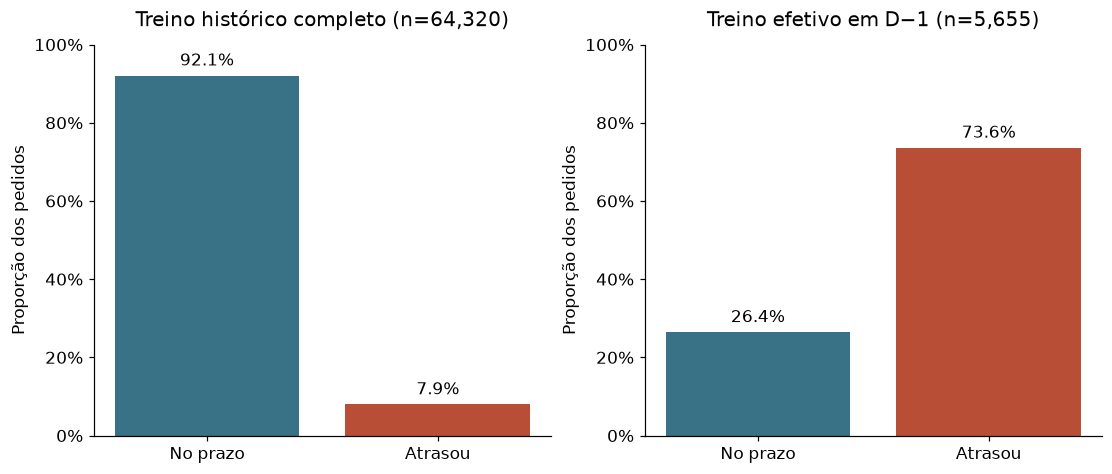

Leitura: condicionar a pedidos ainda pendentes muda a frequência do alvo.
Não compare diretamente essas proporções com as da antiga MLP na aprovação.


In [19]:
eda = pedidos_d1.iloc[indice_treino].copy()
treino_historico = pedidos_d1.loc[particao == "train"]
classes = pd.DataFrame({"Treino histórico completo": treino_historico.late.value_counts().reindex([0, 1], fill_value=0),
                        "Treino efetivo em D−1": eda.late.value_counts().reindex([0, 1], fill_value=0)})
classes.index = ["No prazo", "Atrasou"]
display(classes)
fig, eixos = plt.subplots(1, 2, figsize=(10, 4.2), layout="constrained")
for ax, nome in zip(eixos, classes.columns):
    proporcao = classes[nome] / classes[nome].sum()
    barras = ax.bar(proporcao.index, proporcao, color=[CORES["pontual"], CORES["atraso"]])
    ax.bar_label(barras, labels=[f"{v:.1%}" for v in proporcao], padding=4)
    ax.set(title=f"{nome} (n={classes[nome].sum():,})", ylabel="Proporção dos pedidos", ylim=(0, 1))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
plt.show()
print("Leitura: condicionar a pedidos ainda pendentes muda a frequência do alvo.")
print("Não compare diretamente essas proporções com as da antiga MLP na aprovação.")

### 5.2. Volume e taxa de atraso variam no tempo?

O volume abaixo é de compras da parte histórica de treino, não de pedidos
recebidos por dia em produção. Meses de borda podem ser parciais e meses com
poucos pedidos produzem taxas instáveis. Por isso, meses com menos de 30 pedidos
ficam **sem ponto na curva de taxa**, mas aparecem na tabela de auditoria. Isso
não remove pedidos do treino. Meses sem compras têm volume zero e taxa indefinida.
Mudanças são associações temporais, não evidência de causa.

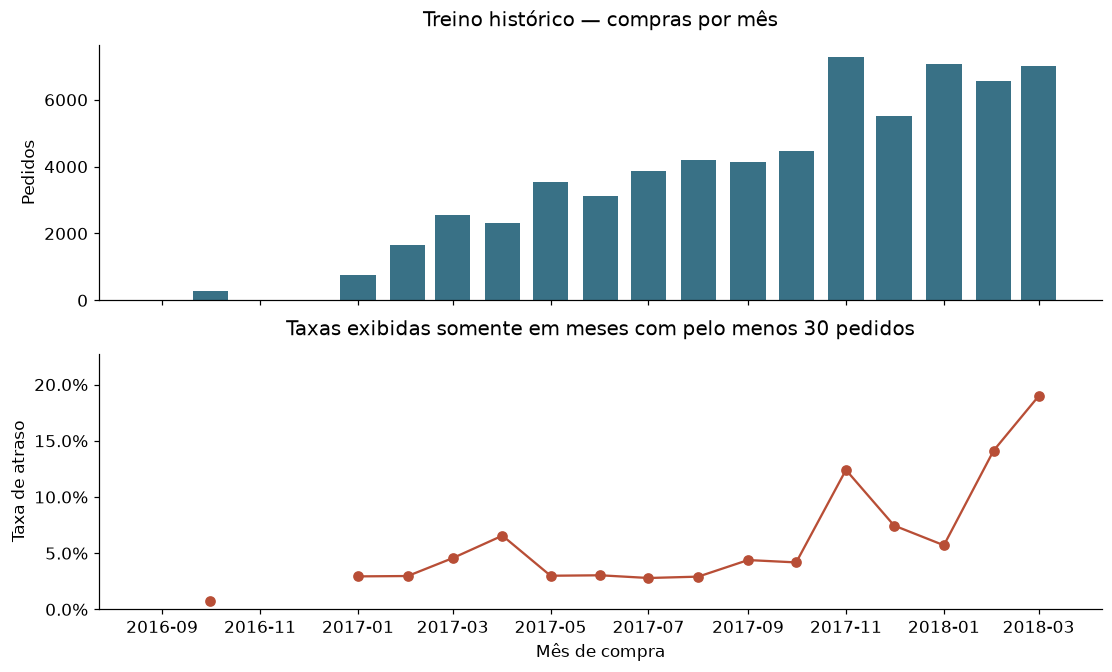

,pedidos,atrasos,taxa
2017-10,4478,187,0.0418
2017-11,7288,904,0.1240
2017-12,5513,411,0.0746
2018-01,7069,403,0.0570
2018-02,6555,926,0.1413
2018-03,7003,1328,0.1896


Meses pequenos ou sem compras (auditoria; não excluídos do treino):


,pedidos,atrasos,taxa
2016-09,1,1,1.0
2016-11,0,0,NaN
2016-12,1,0,0.0


In [20]:
mensal = treino_historico.groupby(treino_historico.order_purchase_timestamp.dt.to_period("M")).agg(
    pedidos=("late", "size"), atrasos=("late", "sum"))
meses = pd.period_range(mensal.index.min(), mensal.index.max(), freq="M")
mensal = mensal.reindex(meses, fill_value=0)
mensal["taxa"] = mensal.atrasos / mensal.pedidos.replace(0, np.nan)
taxa_visivel = mensal.taxa.where(mensal.pedidos >= 30)
fig, eixos = plt.subplots(2, 1, figsize=(10, 6), sharex=True, layout="constrained")
datas = mensal.index.to_timestamp()
eixos[0].bar(datas, mensal.pedidos, width=22, color=CORES["pontual"])
eixos[0].set(title="Treino histórico — compras por mês", ylabel="Pedidos")
eixos[1].plot(datas, taxa_visivel, marker="o", color=CORES["atraso"])
eixos[1].set(title="Taxas exibidas somente em meses com pelo menos 30 pedidos",
             ylabel="Taxa de atraso", xlabel="Mês de compra",
             ylim=(0, min(1.05, max(0.15, taxa_visivel.max() * 1.2))))
eixos[1].yaxis.set_major_formatter(PercentFormatter(1))
plt.show()
display(mensal.tail(6).round(4))
print("Meses pequenos ou sem compras (auditoria; não excluídos do treino):")
display(mensal.loc[mensal.pedidos < 30].round(4))

### 5.3. Distância e peso se distribuem de forma diferente entre as classes?

Boxplots comparam os pendentes do treino efetivo. Ocultamos apenas os pontos
extremos **no desenho**, sem excluir linhas do treinamento. Dados ausentes
não são plotados; zeros decorrentes da agregação de peso continuam sendo uma
limitação da versão reproduzida. Distribuições sobrepostas impedem regras perfeitas.

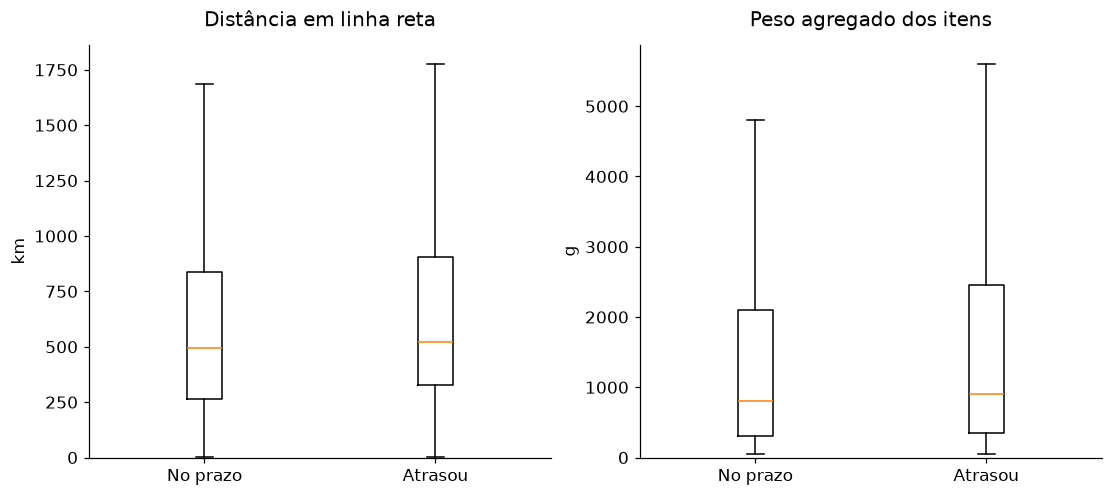

,haversine_km,weight_total,promised_days
late,,,
0,492.7,800.0,22.21
1,520.2,900.0,23.39


In [21]:
fig, eixos = plt.subplots(1, 2, figsize=(10, 4.4), layout="constrained")
for ax, coluna, titulo, unidade in [
    (eixos[0], "haversine_km", "Distância em linha reta", "km"),
    (eixos[1], "weight_total", "Peso agregado dos itens", "g")]:
    grupos = [eda.loc[eda.late.eq(classe), coluna].dropna() for classe in [0, 1]]
    ax.boxplot(grupos, tick_labels=["No prazo", "Atrasou"], showfliers=False)
    ax.set(title=titulo, ylabel=unidade, ylim=(0, None))
plt.show()
display(eda.groupby("late")[["haversine_km", "weight_total", "promised_days"]].median().round(2))

## 6. Formar os atributos que o CatBoost pode receber

### 6.1. Atributos básicos e históricos

`X` contém as características; `y` contém o resultado observado. Não são a mesma
coisa. [`feature_table`](../experimentos/EntregaCertaAI_VER07/src/support/olist_checkpoint.py)
seleciona uma lista explícita de atributos disponíveis no checkpoint.
[`enhanced_features`](../experimentos/EntregaCertaAI_VER07/src/support/ver04_features.py)
adiciona janelas históricas de 30/90 dias e relações logísticas.

Históricos podem se atualizar com entregas conhecidas antes de **cada** checkpoint,
inclusive durante a validação/teste. Isso simula consulta operacional; não retreina
o modelo nem permite usar entregas futuras. As taxas usam suavização fixa, não
uma média calculada com rótulos de todo o dataset.

In [22]:
X_basico, _ = checkpoint.feature_table(pedidos_d1)
X_historicos = historicos.enhanced_features(pedidos_d1, X_basico)
etapas_atributos = {"Básicos e histórico acumulado": X_basico.shape[1],
                    "Janelas e relações logísticas": X_historicos.shape[1]}

# Auditoria amostral independente: só entregas anteriores podem contar no histórico.
amostra = eda.sample(n=min(12, len(eda)), random_state=SEMENTE)
for _, pedido in amostra.iterrows():
    passado = base.loc[base.seller_id.eq(pedido.seller_id)
                       & (base.order_delivered_customer_date < pedido.checkpoint_at)]
    assert pedido.seller_hist_n == len(passado)
    assert pedido.seller_hist_late_n == passado.late.sum()
print("Histórico de vendedor conferido em", len(amostra), "pedidos reais do treino.")

Histórico de vendedor conferido em 12 pedidos reais do treino.


### 6.2. Marketing com informação anterior à compra

O piloto escolhido usa apenas negócios fechados (`closed_only`), não a variante
com MQL. A junção por vendedor aceita somente `won_date <= compra`. Ausências
permanecem ausências. A cobertura baixa limita o que se pode concluir sobre marketing.

In [23]:
marketing, cobertura_marketing = externos.add_marketing(base, PREPARADOS / "olist_closed_deals_dataset.csv")
assert marketing.order_id.equals(base.order_id)
display(pd.Series(cobertura_marketing, name="Marketing — cobertura na coorte").to_frame())

,Marketing — cobertura na coorte
rows_in_source,842.000000
covered_orders_with_prior_win,4409.000000
covered_pct,4.570333


### 6.3. Rodovias e clima histórico publicado

Distâncias rodoviárias são obtidas por municípios, a partir da rede de **maio
de 2024**. Não são distâncias históricas exatas de 2016–2018. O arquivo é lido
em blocos para reduzir memória; esta célula pode demorar alguns minutos.

Clima usa observações agregadas por UF e sua data de disponibilidade. A hipótese
de publicação (sete dias, quando necessária) não é uma medição de latência real.
Não são previsões de chuva futura nem condições exatas da rota do caminhão.

In [24]:
rodovias, cobertura_rodovias = externos.add_roads(base, ARQUIVO_RODOVIAS, PREPARADOS / "municipios_ibge.csv")
clima, cobertura_clima = externos.add_weather(pedidos_d1, PREPARADOS / "weather_daily.csv")
for tabela in [rodovias, clima]:
    assert tabela.order_id.equals(base.order_id)
coberturas = {"marketing": cobertura_marketing, "rodovias": cobertura_rodovias, "clima": cobertura_clima}
display(pd.DataFrame({"Fonte": ["Marketing anterior", "Rodovias 2024", "Chuva UF de destino"],
                       "Cobertura (%)": [cobertura_marketing["covered_pct"], cobertura_rodovias["matched_pct"],
                                           cobertura_clima["customer_weather_coverage_pct"]]}).round(2))

,Fonte,Cobertura (%)
0,Marketing anterior,4.57
1,Rodovias 2024,15.70
2,Chuva UF de destino,99.99


### 6.4. Finalizar os 111 atributos e separar categorias

Concatenamos linhas já alinhadas por `order_id`. A VER0.7 adiciona médias passadas
de atraso/trânsito e relações entre distância e prazo. O código dessas fórmulas
está em [`add_practical_features`](../experimentos/EntregaCertaAI_VER07/src/benchmark_ver07.py).

Números infinitos viram ausentes; categorias ausentes recebem `__MISSING__`.
O CatBoost recebe categorias como texto e trata nulos numéricos nativamente.
Árvores não exigem a padronização/one-hot da MLP: **111 atributos originais**
não são comparáveis às 159 colunas após one-hot da experiência anterior.

In [40]:
X_enriquecido = pd.concat([X_historicos, marketing.drop(columns="order_id"),
                           rodovias.drop(columns="order_id"), clima.drop(columns="order_id")], axis=1)
X_enriquecido = ver06.clean_categorical(X_enriquecido)
X = ver07.add_practical_features(pedidos_d1, X_enriquecido)
categoricas = X.select_dtypes(include=["object", "string", "category"]).columns.tolist()
numericas = [c for c in X if c not in categoricas]
etapas_atributos["Com fontes externas"] = X_enriquecido.shape[1]
etapas_atributos["VER0.7 final"] = X.shape[1]

proibidas = {"late", "atrasou", "order_delivered_customer_date", "order_delivered_carrier_date",
             "order_status", "review_score", "order_id", "real_delay_days", "real_transit_days"}
assert not proibidas.intersection(X.columns)
assert X.columns.is_unique and X.shape == (len(base), 111)
assert not np.isinf(X[numericas].to_numpy(dtype=float)).any()
modelo_recebido = CatBoostClassifier()
modelo_recebido.load_model(str(PACOTE / "results/pilot_Dminus1_CB07_closed_only.cbm"))
assert X.columns.tolist() == modelo_recebido.feature_names_
assert categoricas == [X.columns[i] for i in modelo_recebido.get_cat_feature_indices()]
display(pd.Series(etapas_atributos, name="Quantidade de atributos").to_frame())
print("Categorias:", len(categoricas), "| Numéricos:", len(numericas))

X.to_csv('pedidos.csv')

,Quantidade de atributos
Básicos e histórico acumulado,57
Janelas e relações logísticas,78
Com fontes externas,95
VER0.7 final,111


Categorias: 12 | Numéricos: 99


### 6.5. Onde faltam informações no treino?

Para categorias, o marcador `__MISSING__` também conta como ausência. Não
preenchemos a matriz rodoviária ou marketing com registros inventados. Um campo
com muita falta pode funcionar como indicador de cobertura, sem representar
um efeito causal da variável original.

In [59]:
X_treino = X.iloc[indice_treino].copy()
y_treino = y[indice_treino]
ausencias = X_treino.isna().mean()
ausencias.loc[categoricas] = X_treino[categoricas].eq("__MISSING__").mean()
mais_ausentes = ausencias.sort_values(ascending=False).head(20).sort_values()
fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
barras = ax.barh(mais_ausentes.index, mais_ausentes, color=CORES["pontual"])
ax.bar_label(barras, labels=[f"{v:.1%}" for v in mais_ausentes], padding=3, fontsize=9)
ax.set(title="Treino efetivo — 12 atributos com mais ausências", xlabel="Fração de pedidos sem informação", xlim=(0, 1.13))
ax.xaxis.set_major_formatter(PercentFormatter(1))
plt.show()
print("Nulos numéricos são permitidos; textos categóricos ausentes já foram identificados.")

print(X_treino.info())
print(ausencias)

KeyError: "['marketing_business_segment', 'marketing_lead_type', 'marketing_lead_behaviour_profile', 'marketing_has_company', 'marketing_has_gtin', 'marketing_average_stock', 'marketing_business_type'] not in index"

## 7. Treinar o CatBoost do zero

O CatBoost combina árvores sucessivas. `iterations=420` é a quantidade de árvores;
`depth=5`, sua profundidade; `learning_rate=0.035`, o tamanho dos ajustes;
`l2_leaf_reg=12`, regularização. `Balanced` altera o peso das classes **apenas
na função de perda**: não cria pedidos nem balanceia artificialmente o teste.

No treino efetivo desta versão, atrasos são a classe majoritária. Assim, não
assuma que `Balanced` sempre aumenta o peso dos atrasos: o peso depende das
frequências de `y_treino`. Esse recorte é diferente do antigo treino na aprovação.

Mantemos os parâmetros e a seed 42 do piloto recebido. Não há busca de parâmetros
nem early stopping neste fluxo, pois o piloto original usa 420 iterações fixas.
Adicionar isso seria um novo experimento. Nenhuma validação/teste é passada a `fit`.

In [27]:
display(pd.Series(PARAMETROS, name="Configuração do piloto").to_frame())
display(pd.Series(y_treino).value_counts().sort_index().rename_axis("Alvo").to_frame("Treino efetivo"))
inicio_treino = perf_counter()
modelo = CatBoostClassifier(**PARAMETROS)
modelo.fit(X_treino, y_treino, cat_features=categoricas)
tempo_treino = perf_counter() - inicio_treino
print(f"Treino concluído: {len(X_treino):,} pedidos, {X_treino.shape[1]} atributos, {tempo_treino:.1f} segundos.")

,Configuração do piloto
iterations,420
depth,5
learning_rate,0.035
l2_leaf_reg,12.0
auto_class_weights,Balanced
random_strength,0.6
rsm,0.85
loss_function,Logloss
random_seed,42
thread_count,4


,Treino efetivo
Alvo,
0,1494
1,4161


Treino concluído: 5,655 pedidos, 111 atributos, 26.5 segundos.


### 7.1. A perda de treino caiu?

Logloss menor indica melhor ajuste ao treino sob os pesos escolhidos. Isso
**não garante** melhora em pedidos futuros. A conclusão sobre utilidade virá
das métricas de validação/teste e do tamanho da fila, não desta curva isolada.

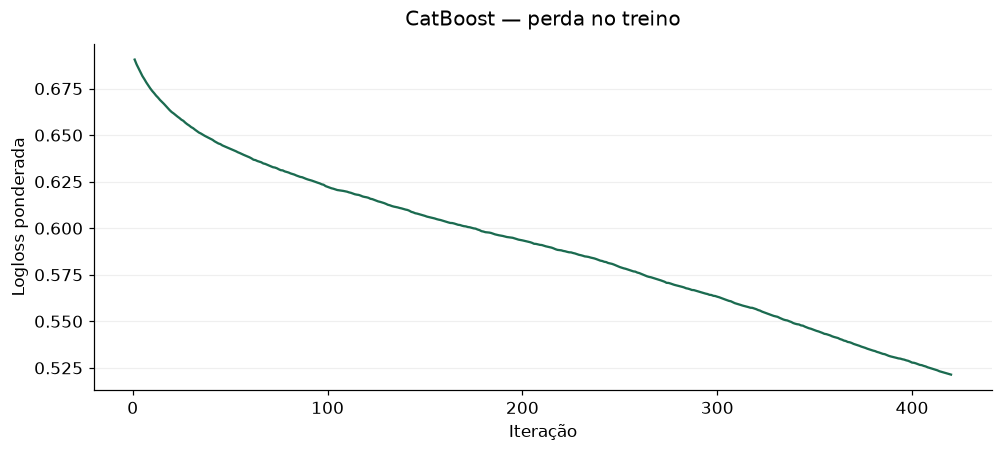

In [28]:
perdas = modelo.get_evals_result()["learn"]["Logloss"]
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
ax.plot(np.arange(1, len(perdas) + 1), perdas, color=CORES["modelo"])
ax.set(title="CatBoost — perda no treino", xlabel="Iteração", ylabel="Logloss ponderada")
ax.grid(axis="y", alpha=0.2)
plt.show()

## 8. Transformar scores em fila e avaliar a validação

### 8.1. A regra operacional é diária

O modelo gera um score; a capacidade determina a fila. Por dia, selecionamos
`ceil(0,65 × pendentes)` pelos maiores scores. `ceil` arredonda para cima:
um dia com poucos pedidos pode ultrapassar 65% efetivamente. Empates seguem a
ordem cronológica original. Um pedido já entregue não é pontuado, recebendo
zero convencional. Esse zero não significa uma probabilidade estimada.

In [29]:
def fila_diaria(scores, idx):
    fila = pd.DataFrame({"posicao": np.arange(len(idx)), "score": scores,
                         "pendente": pendente[idx],
                         "dia": pedidos_d1.checkpoint_at.iloc[idx].to_numpy()})
    alertas = np.zeros(len(idx), dtype=int)
    for _, grupo in fila.loc[fila.pendente].groupby("dia", sort=False):
        quantidade = math.ceil(len(grupo) * FRACAO_FILA)
        escolhidos = grupo.sort_values(["score", "posicao"], ascending=[False, True]).head(quantidade)
        alertas[escolhidos.posicao.to_numpy()] = 1
    return alertas

def pontuar(modelo_usado, idx):
    scores = np.zeros(len(idx), dtype=float)
    ativos = pendente[idx]
    scores[ativos] = modelo_usado.predict_proba(X.iloc[idx[ativos]])[:, 1]
    return scores

def avaliar(nome, idx, scores, alertas):
    real, ativos = y[idx], pendente[idx]
    tn, fp, fn, tp = confusion_matrix(real, alertas, labels=[0, 1]).ravel()
    return dict(modelo=nome, pedidos=len(idx), pendentes=int(ativos.sum()),
        atrasos=int(real.sum()), fila=int(alertas.sum()), tp=int(tp), fp=int(fp), fn=int(fn), tn=int(tn),
        precision=precision_score(real, alertas, zero_division=0), recall=recall_score(real, alertas, zero_division=0),
        f1=f1_score(real, alertas, zero_division=0), accuracy_total=accuracy_score(real, alertas),
        accuracy_pendentes=accuracy_score(real[ativos], alertas[ativos]),
        ap_pendentes=average_precision_score(real[ativos], scores[ativos]),
        fila_total=float(alertas.mean()), fila_pendentes=float(alertas.sum() / ativos.sum()))

scores_validacao = pontuar(modelo, indice_validacao)
fila_validacao = fila_diaria(scores_validacao, indice_validacao)
np.testing.assert_array_equal(fila_validacao, ver07.top_ratio_policy(scores_validacao,
    pendente[indice_validacao], pedidos_d1.checkpoint_at.iloc[indice_validacao], FRACAO_FILA))
metricas_validacao = avaliar("CatBoost", indice_validacao, scores_validacao, fila_validacao)
display(pd.Series(metricas_validacao, name="Validação efetiva").to_frame())

,Validação efetiva
modelo,CatBoost
pedidos,12175
pendentes,1017
atrasos,674
fila,680
tp,480
fp,200
fn,194
tn,11301
precision,0.705882


### 8.2. Comparar com regras simples usando a mesma capacidade

Uma boa comparação não é apenas “acertar todos os pontuais”. Testamos rankings
simples baseados em idade do pedido, trânsito e despacho. Todos recebem a mesma
cota diária. Escolhemos a regra com maior F1 **na validação**, não no teste.
Os scores dessas regras são ordenadores, não probabilidades.

In [30]:
regras = {
    "Idade do pedido": pedidos_d1.age_days.to_numpy(),
    "Tempo em trânsito": pedidos_d1.in_transit_days.fillna(-1).to_numpy(),
    "Não despachado, depois idade": (pedidos_d1.not_dispatched.astype(float) * 1000 + pedidos_d1.age_days.fillna(0)).to_numpy(),
    "Tempo após limite de envio": pedidos_d1.shipping_limit_age_days.fillna(-100).to_numpy(),
}
resultados_regras = []
for nome, scores in regras.items():
    alertas = fila_diaria(scores[indice_validacao], indice_validacao)
    resultados_regras.append(avaliar(nome, indice_validacao, scores[indice_validacao], alertas))
tabela_regras = pd.DataFrame(resultados_regras).set_index("modelo")
melhor_regra = tabela_regras.f1.idxmax()
display(tabela_regras[["fila", "tp", "fp", "fn", "precision", "recall", "f1"]].round(4))
print("Regra escolhida pela validação:", melhor_regra)

,fila,tp,fp,fn,precision,recall,f1
modelo,,,,,,,
Idade do pedido,680,467,213,207,0.6868,0.6929,0.6898
Tempo em trânsito,680,458,222,216,0.6735,0.6795,0.6765
"Não despachado, depois idade",680,470,210,204,0.6912,0.6973,0.6942
Tempo após limite de envio,680,471,209,203,0.6926,0.6988,0.6957


Regra escolhida pela validação: Tempo após limite de envio


## 9. Avaliar o teste histórico, depois de congelar as escolhas

Os parâmetros, atributos, capacidade e regra de referência já estão definidos.
Não ajustaremos o modelo depois de ver esta tabela. Mesmo com essa ordem correta
no notebook, o histórico de reutilização do teste continua existindo.

**Precision:** dos alertas, quantos eram atrasos? **Recall:** dos atrasos reais,
quantos encontramos? **F1:** equilíbrio entre ambos. **AP:** qualidade do ranking
em vários cortes; calculada por `average_precision_score`, aqui nos pendentes.
Mostramos accuracy total e dos pendentes separadamente para evitar confundir
pedidos já entregues com acertos obtidos pelo classificador.

In [31]:
scores_teste = pontuar(modelo, indice_teste)
fila_teste = fila_diaria(scores_teste, indice_teste)
metricas_teste = avaliar("CatBoost", indice_teste, scores_teste, fila_teste)
scores_regra = regras[melhor_regra][indice_teste]
fila_regra = fila_diaria(scores_regra, indice_teste)
metricas_regra = avaliar(melhor_regra, indice_teste, scores_regra, fila_regra)
tabela_teste = pd.DataFrame([metricas_teste, metricas_regra]).set_index("modelo")
display(tabela_teste[["pedidos", "pendentes", "fila", "tp", "fp", "fn", "tn"]])
display(tabela_teste[["precision", "recall", "f1", "accuracy_total", "accuracy_pendentes",
                      "ap_pendentes", "fila_total", "fila_pendentes"]].round(4))
print("Frações estão entre 0 e 1: multiplique por 100 para ler em porcentagem.")

,pedidos,pendentes,fila,tp,fp,fn,tn
modelo,,,,,,,
CatBoost,18603,1486,990,553,437,119,17494
Tempo após limite de envio,18603,1486,990,470,520,202,17411


,precision,recall,f1,accuracy_total,accuracy_pendentes,ap_pendentes,fila_total,fila_pendentes
modelo,,,,,,,,
CatBoost,0.5586,0.8229,0.6655,0.9701,0.6258,0.7303,0.0532,0.6662
Tempo após limite de envio,0.4747,0.6994,0.5656,0.9612,0.5141,0.6215,0.0532,0.6662


Frações estão entre 0 e 1: multiplique por 100 para ler em porcentagem.


### 9.1. Onde o modelo erra?

A primeira matriz inclui toda a coorte efetiva do teste. A segunda inclui
apenas os pendentes que receberam score. A grande quantidade de verdadeiros
negativos no total inclui pedidos já entregues: não é mérito isolado do CatBoost.
“Na fila” significa indicação de revisão humana, não atraso confirmado.

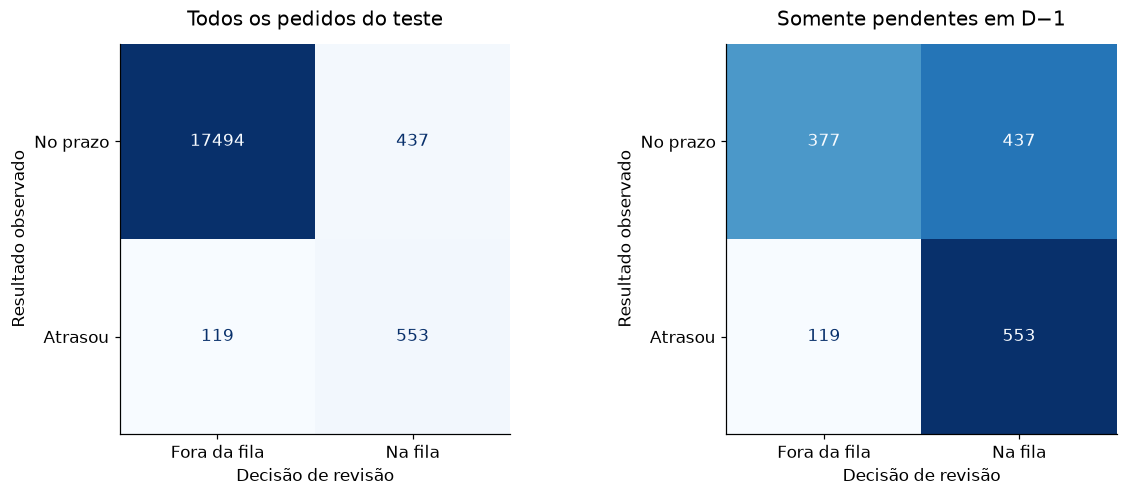

In [32]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 4.4), layout="constrained")
for ax, mascara, titulo in [(eixos[0], np.ones(len(indice_teste), dtype=bool), "Todos os pedidos do teste"),
                             (eixos[1], pendente[indice_teste], "Somente pendentes em D−1")]:
    matriz = confusion_matrix(y[indice_teste][mascara], fila_teste[mascara], labels=[0, 1])
    ConfusionMatrixDisplay(matriz, display_labels=["No prazo", "Atrasou"]).plot(
        ax=ax, values_format="d", cmap="Blues", colorbar=False)
    ax.set(title=titulo, xlabel="Decisão de revisão", ylabel="Resultado observado")
    ax.set_xticklabels(["Fora da fila", "Na fila"])
plt.show()

### 9.2. Precisão e cobertura do ranking

A curva é calculada nos **pendentes**. A linha tracejada indica sua proporção
de atrasos, como referência de ranking aleatório. O ponto da fila diária é
uma política com vários cortes, um por dia; **não precisa ficar sobre a curva
de um único limiar global**. A política usa capacidade, não um corte de score 0,65.

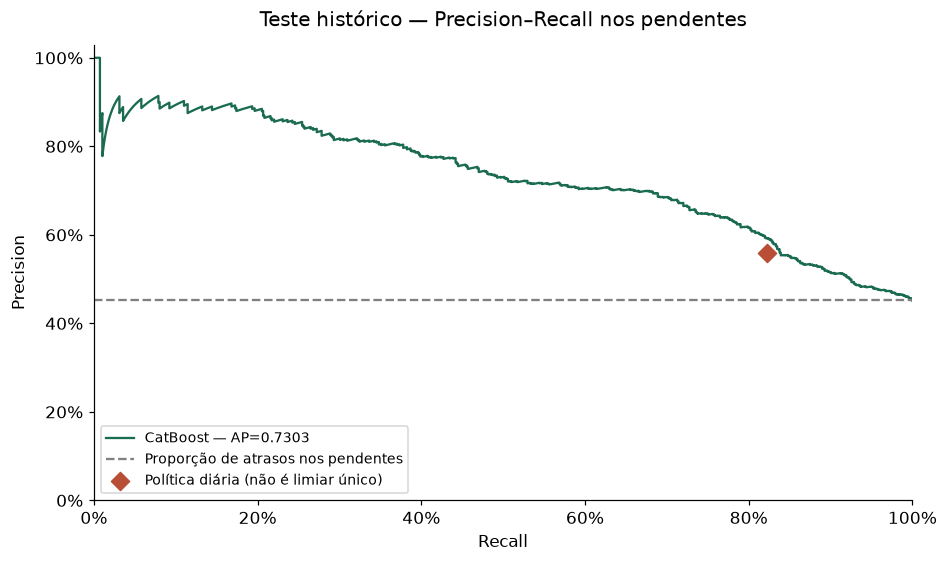

In [33]:
ativos_teste = pendente[indice_teste]
real_pendente = y[indice_teste][ativos_teste]
precisao, revocacao, _ = precision_recall_curve(real_pendente, scores_teste[ativos_teste])
fig, ax = plt.subplots(figsize=(8.5, 5), layout="constrained")
ax.plot(revocacao, precisao, color=CORES["modelo"], label=f"CatBoost — AP={metricas_teste['ap_pendentes']:.4f}")
ax.axhline(real_pendente.mean(), color="gray", linestyle="--", label="Proporção de atrasos nos pendentes")
ax.scatter(metricas_teste["recall"], metricas_teste["precision"], color=CORES["atraso"], marker="D",
           s=70, zorder=3, label="Política diária (não é limiar único)")
ax.set(title="Teste histórico — Precision–Recall nos pendentes", xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1.03))
ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend(loc="lower left", fontsize=9)
plt.show()

### 9.3. Fila e comparação operacional

Com o mesmo orçamento, comparar atrasos encontrados ajuda a medir utilidade
histórica. Isso não mede quantos atrasos uma intervenção conseguiria evitar.
Comparamos aqui a referência escolhida na validação; não escolhemos a regra
que apareceu melhor depois de olhar o teste.

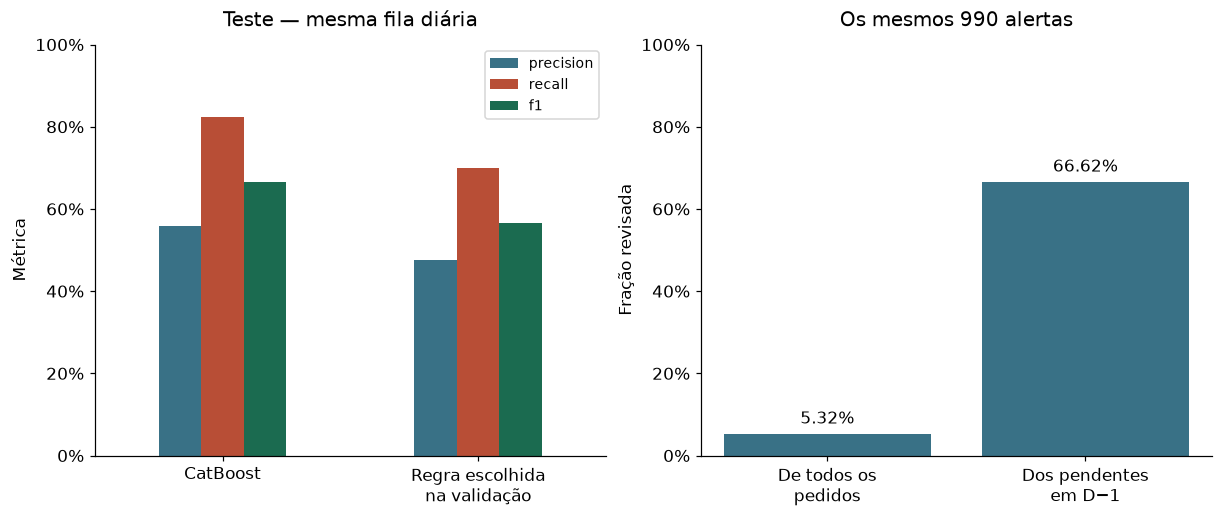

In [34]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 4.6), layout="constrained")
comparacao = tabela_teste[["precision", "recall", "f1"]].copy()
comparacao.index = ["CatBoost", "Regra escolhida\nna validação"]
comparacao.plot.bar(ax=eixos[0], color=["#397186", "#b84e36", "#1b6b50"], rot=0)
eixos[0].set(title="Teste — mesma fila diária", xlabel="", ylabel="Métrica", ylim=(0, 1))
eixos[0].yaxis.set_major_formatter(PercentFormatter(1)); eixos[0].legend(fontsize=9)
valores = [metricas_teste["fila_total"], metricas_teste["fila_pendentes"]]
barras = eixos[1].bar(["De todos os\npedidos", "Dos pendentes\nem D−1"], valores, color=CORES["pontual"])
eixos[1].bar_label(barras, labels=[f"{v:.2%}" for v in valores], padding=4)
eixos[1].set(title=f"Os mesmos {metricas_teste['fila']} alertas", ylabel="Fração revisada", ylim=(0, 1))
eixos[1].yaxis.set_major_formatter(PercentFormatter(1))
plt.show()

### 9.4. Quais atributos o modelo mais utiliza?

Esta é a importância interna do CatBoost (`PredictionValuesChange`), baseada
no modelo treinado. Não é efeito causal nem explicação individual. Atributos
correlacionados podem dividir importância; isso não autoriza afirmar que chuva,
vendedor ou peso causou um atraso específico.

In [58]:
importancias = pd.Series(modelo.feature_importances_, index=X.columns).sort_values()
fig, ax = plt.subplots(figsize=(10, 5.5), layout="constrained")
ax.barh(importancias.tail(20).index, importancias.tail(20), color=CORES["modelo"])
ax.set(title="CatBoost treinado — 12 maiores importâncias", xlabel="Importância interna (pontos de um total de 100)")
plt.show()

ValueError: Length of values (111) does not match length of index (95)

,Fração ausente,Importância (pontos),Remover
road_detour_ratio_2024,86.26%,0.36717432,True
road_km_per_promised_day_2024,86.19%,0.33402345,True
road_km_2024,86.19%,0.28334466,True
marketing_lead_type,99.49%,0.01380943,True
marketing_deal_age_days,99.49%,0.00851623,True
marketing_business_segment,99.49%,0.00469945,True
marketing_has_company,100.00%,0.00000000,True
marketing_lead_behaviour_profile,99.98%,0.00000000,True
marketing_business_type,99.49%,0.00000000,True
marketing_average_stock,100.00%,0.00000000,True


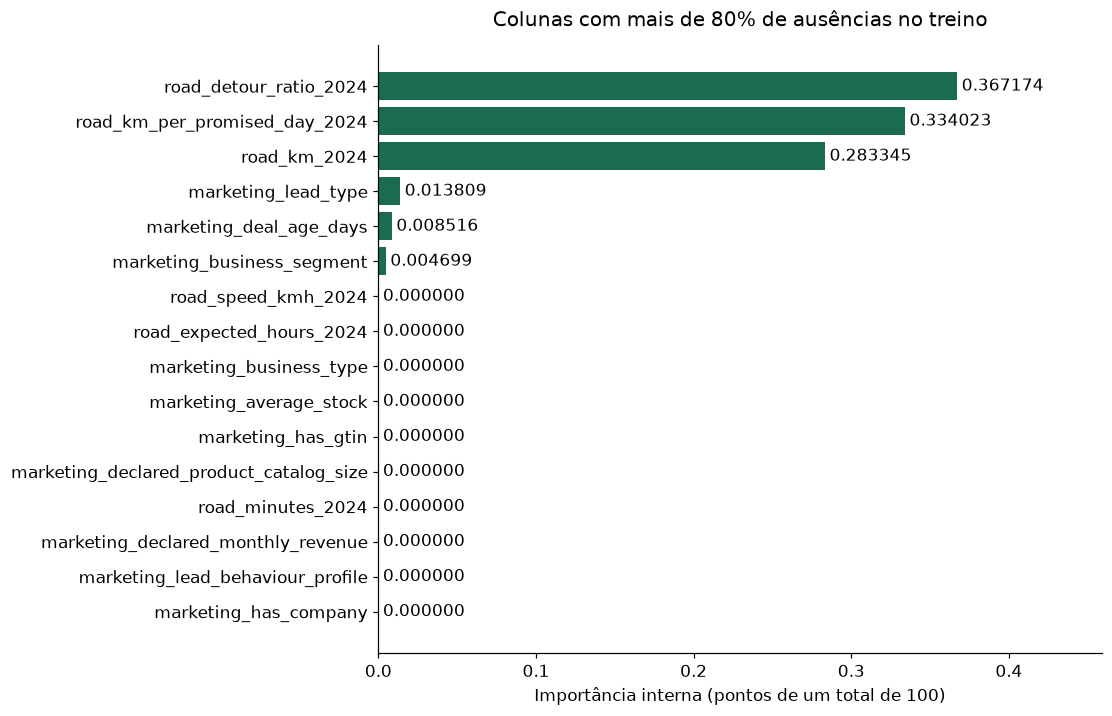

Importância somada dessas colunas: 1.011568 pontos.
Colunas removidas no experimento: ['road_detour_ratio_2024', 'road_km_per_promised_day_2024', 'road_km_2024', 'marketing_lead_type', 'marketing_deal_age_days', 'marketing_business_segment', 'marketing_has_company', 'marketing_lead_behaviour_profile', 'marketing_business_type', 'marketing_average_stock', 'marketing_has_gtin', 'marketing_declared_product_catalog_size', 'road_minutes_2024', 'marketing_declared_monthly_revenue', 'road_expected_hours_2024', 'road_speed_kmh_2024']
Novo modelo treinado com 95 atributos.


,Atributos,AP na validação pendente
Modelo,,
Original,111,0.755303
Sem colunas de importância zero,95,0.757518


Importância zero descreve o modelo atual; não prova ausência de efeito em um novo treino.


In [ ]:
# Diagnóstico das colunas com mais de 80% de ausências no treino.
# Usa todas as importâncias do modelo, não apenas as 20 exibidas no gráfico.
importancias_ausencias = pd.Series(
    modelo.feature_importances_, index=modelo.feature_names_, name="Importância (pontos)"
)
analise_ausencias = pd.concat([
    ausencias.rename("Fração ausente"), importancias_ausencias
], axis=1)
analise_ausencias = analise_ausencias.loc[
    analise_ausencias["Fração ausente"].gt(0.80)
].sort_values("Importância (pontos)", ascending=False)
assert analise_ausencias["Importância (pontos)"].notna().all(), "Há colunas sem importância correspondente no modelo."
# Critério conservador: só remover importância exatamente zero.
analise_ausencias["Remover"] = analise_ausencias["Importância (pontos)"].lt(0.4)
colunas_sem_influencia = analise_ausencias.index[analise_ausencias["Remover"]].tolist()
display(analise_ausencias.style.format({
    "Fração ausente": "{:.2%}", "Importância (pontos)": "{:.8f}"
}))

if not analise_ausencias.empty:
    dados_grafico = analise_ausencias.sort_values("Importância (pontos)")
    fig, ax = plt.subplots(figsize=(10, max(3, 0.4 * len(dados_grafico))), layout="constrained")
    barras = ax.barh(dados_grafico.index, dados_grafico["Importância (pontos)"], color=CORES["modelo"])
    ax.bar_label(barras, labels=[f"{v:.6f}" for v in dados_grafico["Importância (pontos)"]], padding=3)
    ax.margins(x=0.25)
    ax.set(title="Colunas com mais de 80% de ausências no treino",
           xlabel="Importância interna (pontos de um total de 100)")
    plt.show()
    print(f"Importância somada dessas colunas: {analise_ausencias['Importância (pontos)'].sum():.6f} pontos.")
else:
    print("Nenhuma coluna tem mais de 80% de ausências no treino.")

# Experimento separado: evita invalidar scores e avaliações já calculados acima.
# O drop ocorre antes deste novo fit, mantendo X e modelo originais intactos.
modelo_sem_ausentes = None
X_sem_ausentes = X.drop(columns=colunas_sem_influencia).copy()
categoricas_sem_ausentes = [c for c in categoricas if c in X_sem_ausentes.columns]
if colunas_sem_influencia:
    print("Colunas removidas no experimento:", colunas_sem_influencia)
    X_treino_sem_ausentes = X_sem_ausentes.iloc[indice_treino].copy()
    modelo_sem_ausentes = CatBoostClassifier(**PARAMETROS)
    modelo_sem_ausentes.fit(X_treino_sem_ausentes, y_treino,
                           cat_features=categoricas_sem_ausentes)
    print(f"Novo modelo treinado com {X_treino_sem_ausentes.shape[1]} atributos.")
    # Compara na validação; não usa o teste para decidir a remoção.
    idx_comparacao = indice_validacao[pendente[indice_validacao]]
    if len(idx_comparacao):
        comparacao_ausencias = []
        for nome, estimador, matriz in [
            ("Original", modelo, X),
            ("Sem colunas de importância zero", modelo_sem_ausentes, X_sem_ausentes)
        ]:
            prob = estimador.predict_proba(matriz.iloc[idx_comparacao])[:, 1]
            comparacao_ausencias.append({"Modelo": nome, "Atributos": matriz.shape[1],
                "AP na validação pendente": average_precision_score(y[idx_comparacao], prob)})
        display(pd.DataFrame(comparacao_ausencias).set_index("Modelo"))
    else:
        print("Sem pedidos pendentes na validação para comparar os modelos.")
else:
    print("Nenhuma coluna atende aos dois critérios (>80% ausente e importância zero); nenhum drop ou novo treino realizado.")
print("Importância zero descreve o modelo atual; não prova ausência de efeito em um novo treino.")


In [60]:
importancias = pd.Series(modelo.feature_importances_, index=X.columns).sort_values()
fig, ax = plt.subplots(figsize=(10, 15.5), layout="constrained")
ax.barh(importancias.index, importancias, color=CORES["modelo"])
ax.set(title="CatBoost treinado — 12 maiores importâncias", xlabel="Importância interna (pontos de um total de 100)")
plt.show()

ValueError: Length of values (111) does not match length of index (95)

### 9.5. O treino novo reproduziu o piloto recebido?

Comparar só F1 não basta: conferimos IDs, scores e alertas. Diferenças de versão,
plataforma ou dados podem mudar o treino; se houver divergência, ela será exibida,
sem trocar resultados por números do pacote. O arquivo `.cbm` é um artefato
binário; o código de treinamento é a célula 7 e os scripts de referência.

In [36]:
referencia_teste = pd.read_csv(PACOTE / "results/pilot_CB07_closed_only_test_predictions.csv")
np.testing.assert_array_equal(pedidos_d1.order_id.iloc[indice_teste], referencia_teste.order_id)
scores_recebido = pontuar(modelo_recebido, indice_teste)
np.testing.assert_allclose(scores_recebido, referencia_teste.score, atol=1e-9, rtol=0)
np.testing.assert_array_equal(fila_diaria(scores_recebido, indice_teste), referencia_teste.alert)
erro_maximo = float(np.max(np.abs(scores_teste - scores_recebido)))
mesma_fila = bool(np.array_equal(fila_teste, referencia_teste.alert.to_numpy()))
reproduziu_treino = erro_maximo <= 1e-9 and mesma_fila
print("Maior diferença de score entre treino novo e modelo recebido:", erro_maximo)
print("Mesma fila:", mesma_fila)
print("Treino reproduzido dentro da tolerância:", reproduziu_treino)
if not reproduziu_treino:
    display(Markdown("**Atenção:** o treino novo divergiu. Seus resultados são os calculados acima; investigue versões e dados antes de promover o modelo."))

# Verifica também as entradas já integradas, se estiverem disponíveis neste computador.
arquivo_ativo = RAIZ / "Modelos/catboost_ver07/pedidos_d1.parquet"
if arquivo_ativo.is_file():
    entradas_ativas = pd.read_parquet(arquivo_ativo).set_index("order_id")
    atuais = X.copy(); atuais.index = pedidos_d1.order_id
    pd.testing.assert_frame_equal(atuais.loc[entradas_ativas.index], entradas_ativas[X.columns], check_dtype=False)
    print("As 111 entradas da validação/teste coincidem com as integradas à aplicação.")

Maior diferença de score entre treino novo e modelo recebido: 0.0
Mesma fila: True
Treino reproduzido dentro da tolerância: True
As 111 entradas da validação/teste coincidem com as integradas à aplicação.


## 10. Salvar e recarregar sem alterar a aplicação

Cada execução gera uma pasta própria contendo: modelo treinado, dataset analítico
em Parquet, previsões de teste em CSV e registro JSON de parâmetros/métricas.
JSON aqui guarda configuração e resultados; não é um dataset inventado.

O dataset analítico inclui **o alvo para estudo** e uma coluna `uso`: treino,
validação, teste ou excluído pelo protocolo. Não entregue a tabela inteira ao
modelo: suas entradas são somente as colunas de `X`. O Parquet preserva tipos
e ocupa menos espaço que o CSV; abra com `pd.read_parquet(...)`.

In [37]:
SAIDA.mkdir(parents=True, exist_ok=False)
modelo.save_model(str(SAIDA / "catboost_treinado.cbm"))
dataset = X.copy()
dataset.insert(0, "order_id", pedidos_d1.order_id)
dataset["checkpoint_at"] = pedidos_d1.checkpoint_at
dataset["atrasou"] = y
dataset["pendente"] = pendente
dataset["uso"] = "excluido_do_ajuste_e_avaliacao"
for nome, idx in indices.items():
    dataset.loc[idx, "uso"] = nome
dataset.to_parquet(SAIDA / "dataset_analitico_d1.parquet", index=False)

previsoes = pd.DataFrame({"order_id": pedidos_d1.order_id.iloc[indice_teste].to_numpy(),
    "checkpoint_at": pedidos_d1.checkpoint_at.iloc[indice_teste].to_numpy(),
    "atrasou": y[indice_teste], "pendente": ativos_teste,
    "score_atraso": scores_teste, "prioridade": fila_teste})
previsoes.to_csv(SAIDA / "previsoes_teste.csv", index=False)
modelo_reaberto = CatBoostClassifier()
modelo_reaberto.load_model(str(SAIDA / "catboost_treinado.cbm"))
np.testing.assert_allclose(pontuar(modelo_reaberto, indice_teste), scores_teste, atol=1e-12, rtol=0)
np.testing.assert_array_equal(fila_diaria(pontuar(modelo_reaberto, indice_teste), indice_teste), fila_teste)
for caminho, digest in hashes_antes.items():
    assert sha256(caminho) == digest, f"Arquivo anterior alterado: {caminho}"
for caminho in [ARQUIVO_OLIST, ARQUIVO_RODOVIAS]:
    assert sha256(caminho) == hashes_fontes[caminho.name]
print("Modelo recarregado: mesmos scores e alertas. Fontes e versões anteriores preservadas.")

Modelo recarregado: mesmos scores e alertas. Fontes e versões anteriores preservadas.


### 10.1. Registrar evidências e ler o resultado desta execução

Guardamos também o baseline, as versões, os cortes e as limitações para o artigo.
Uma regra alternativa do pacote (`not_dispatched_then_age`) obteve F1 de cerca
de 66,43% no teste exploratório, mas não foi a selecionada pela validação.
Não há demonstração de superioridade estatística sobre todas as regras simples.

In [38]:
registro = {"execucao_utc": EXECUCAO, "python": sys.version, "versoes": VERSOES,
    "hashes_fontes": hashes_fontes, "parametros": PARAMETROS,
    "colunas_entrada": X.columns.tolist(), "categoricas": categoricas,
    "colunas_metadados_e_alvo": [c for c in dataset if c not in X],
    "checkpoint": "D-1 00:00", "fracao_diaria_pendentes": FRACAO_FILA,
    "inicio_validacao": str(inicio_validacao), "inicio_teste": str(inicio_teste),
    "n_treino": len(indice_treino), "tempo_treino_segundos": tempo_treino,
    "validacao": metricas_validacao, "teste": metricas_teste,
    "regra_selecionada_validacao": melhor_regra, "teste_regra": metricas_regra,
    "coberturas": coberturas, "erro_maximo_retreino": erro_maximo,
    "mesma_fila_recebida": mesma_fila, "reproduziu_treino": reproduziu_treino,
    "model_sha256": sha256(SAIDA / "catboost_treinado.cbm"),
    "teste_reutilizado": True, "cota_pos_exploracao": True, "dados_sinteticos": False,
    "arquivos_anteriores_inalterados": True}
(SAIDA / "resultados.json").write_text(json.dumps(registro, ensure_ascii=False, indent=2), encoding="utf-8")
m = metricas_teste
display(Markdown(f"""### Resultado calculado nesta execução
- Treino efetivo: **{len(indice_treino):,} pedidos** e **{X.shape[1]} atributos**.
- Teste: **{m['pedidos']:,} pedidos**, dos quais **{m['pendentes']:,} pendentes** em D−1.
- Encontrados **{m['tp']} de {m['atrasos']} atrasos**; **{m['fn']} não encontrados** e **{m['fp']} falsos alertas**.
- Precision **{m['precision']:.2%}**, recall **{m['recall']:.2%}**, F1 **{m['f1']:.2%}**, AP nos pendentes **{m['ap_pendentes']:.4f}**.
- **{m['fila']} revisões**: **{m['fila_total']:.2%}** da coorte total e **{m['fila_pendentes']:.2%}** dos pendentes.
- Baseline selecionado na validação: **{melhor_regra}**, F1 no teste **{metricas_regra['f1']:.2%}**.
- Resultados **exploratórios**. Não medimos redução real de atrasos ou ROI.
"""))
print("Arquivos desta execução:", SAIDA)

### Resultado calculado nesta execução
- Treino efetivo: **5,655 pedidos** e **111 atributos**.
- Teste: **18,603 pedidos**, dos quais **1,486 pendentes** em D−1.
- Encontrados **553 de 672 atrasos**; **119 não encontrados** e **437 falsos alertas**.
- Precision **55.86%**, recall **82.29%**, F1 **66.55%**, AP nos pendentes **0.7303**.
- **990 revisões**: **5.32%** da coorte total e **66.62%** dos pendentes.
- Baseline selecionado na validação: **Tempo após limite de envio**, F1 no teste **56.56%**.
- Resultados **exploratórios**. Não medimos redução real de atrasos ou ROI.


Arquivos desta execução: c:\Users\cpedr\Documents\Documentos\TCS\projeto\EntregaCerta-AI\Modelos\notebook_ver07\20261117_231715_acb863


## O que explicar à banca e o que fazer depois

1. **Dados reais → Pandas:** sete tabelas Olist, agregação por pedido, rótulo
   observado e enriquecimentos documentados. Datas futuras ficam fora de `X`.
2. **ML:** CatBoost treinado nos pendentes com desfecho conhecido a tempo;
   comparação com regras simples e avaliação com denominadores explícitos.
3. **Aplicação:** o backend já usa a versão recebida em `Modelos/catboost_ver07/`.
   Ele consulta os atributos no PostgreSQL, calcula scores e aplica a cota diária.
   Este notebook **não promove automaticamente** o modelo recém-treinado.
4. **Limitações:** coorte de entregues, vendedor de referência, peso parcialmente
   ausente, aproximação de CEP/UF, rede rodoviária de 2024, teste reutilizado,
   cota pós-exploração e menor tempo de ação em D−1. Associação não é causa.
5. **Próximo experimento:** obter um período novo e ainda não consultado;
   congelar modelo, política e protocolo antes de avaliá-lo. Não continuar
   ajustando a mesma base de teste até obter a métrica desejada.

**Estudos opcionais ficam fora desta sequência:** MLP/CTGAN/PCA permanecem nos
notebooks antigos. O pacote original e o modelo ativo não foram sobrescritos.
Para abrir a aplicação já integrada, siga o [guia de inicialização](../Docs/instalacao_novo_pc.md).